In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [2]:

perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [3]:
# 훈련데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)


In [5]:
# 훈련데이터 2차원 배열 변경
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)


In [ ]:
# 다항회기 형태로 변경 - 컬럼을 2개로 증가시킴.
# 제공되는 라이브러리 사용
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))
train_poly

array([[ 756.25,   27.5 ],
       [ 552.25,   23.5 ],
       [ 225.  ,   15.  ],
       [ 349.69,   18.7 ],
       [ 484.  ,   22.  ],
       [ 484.  ,   22.  ],
       [ 302.76,   17.4 ],
       [ 756.25,   27.5 ],
       [1075.84,   32.8 ],
       [ 484.  ,   22.  ],
       [ 745.29,   27.3 ],
       [1296.  ,   36.  ],
       [ 441.  ,   21.  ],
       [ 756.25,   27.5 ],
       [1521.  ,   39.  ],
       [1600.  ,   40.  ],
       [ 823.69,   28.7 ],
       [1332.25,   36.5 ],
       [ 384.16,   19.6 ],
       [ 702.25,   26.5 ],
       [1936.  ,   44.  ],
       [1764.  ,   42.  ],
       [ 576.  ,   24.  ],
       [1600.  ,   40.  ],
       [1190.25,   34.5 ],
       [1600.  ,   40.  ],
       [1521.  ,   39.  ],
       [1521.  ,   39.  ],
       [ 453.69,   21.3 ],
       [1369.  ,   37.  ],
       [ 441.  ,   21.  ],
       [ 625.  ,   25.  ],
       [1225.  ,   35.  ],
       [1600.  ,   40.  ],
       [ 784.  ,   28.  ],
       [ 900.  ,   30.  ],
       [ 576.  ,   24.  ],
 

In [11]:
# 데이터 학습 
lr =LinearRegression()
lr.fit(train_poly,train_label)

# 데이터 예측
predict = lr.predict(test_poly)
print(predict)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
score,score2


[1054.92131142  702.86212327  108.88476008  131.31315472 1054.92131142
  228.27886579   53.35572863   88.41572419    4.51625232  143.26211157
   -5.83515534  143.26211157   28.50273951  148.17884942]


(0.9633447344906428, 0.9941237412668799)

In [30]:
lr.coef_,lr.intercept_
l = input('농어길이')
l = float(l)
w = lr.predict([[l**2,l]])
print(f'{w[0]:-2f}g')

point = np.arange(10,51)

1554.807854g


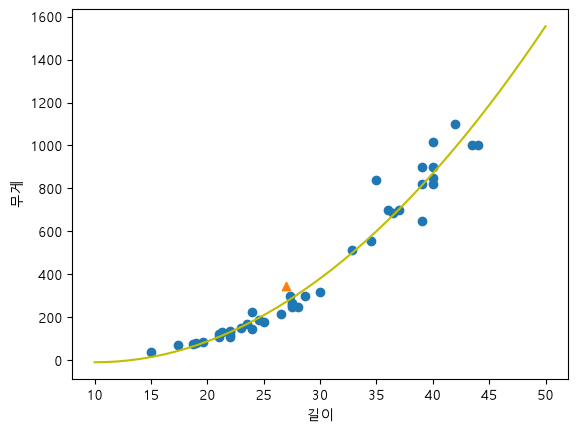

In [38]:
# 산점도 그래프
plt.scatter(train_data,train_label)
plt.scatter(27,345.2,marker='^')
# plt.plot([10,50],[10*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_],color='r')
plt.plot(point,point**2*lr.coef_[0]+point*lr.coef_[1]+lr.intercept_,color='y')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()